### Setup

In [59]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA_DIR = next(p for p in (Path("data/processed"), Path("../data/processed"))
                if (p / "paysim_features.parquet").exists())
MODEL_DIR = DATA_DIR.parent.parent / "models"
MODEL_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
TARGET, SPLIT_KEY = "isFraud", "step"
N_TRIALS = 30          # 30 is enough to learn the workflow; raise to 60-100 for a final run
EXPERIMENT_NAME = "paysim-fraud-xgboost"

## Load the dataset, the feature set and splits

In [60]:
meta = json.loads((MODEL_DIR / "model_meta.json").read_text())
df = pd.read_parquet(DATA_DIR / "paysim_features.parquet").sort_values(SPLIT_KEY, kind="stable").reset_index(drop=True)

FEATURES = meta["features"]
train_end, valid_end = meta["split"]["train_end_step"], meta["split"]["valid_end_step"]

train = df[df[SPLIT_KEY] <= train_end]
valid = df[(df[SPLIT_KEY] > train_end) & (df[SPLIT_KEY] <= valid_end)]
test = df[df[SPLIT_KEY] > valid_end]
y_train, y_valid, y_test = train[TARGET], valid[TARGET], test[TARGET]

assert train[SPLIT_KEY].max() < valid[SPLIT_KEY].min() and valid[SPLIT_KEY].max() < test[SPLIT_KEY].min()
SPW_FULL = (y_train == 0).sum() / (y_train == 1).sum()

print("feature set :", meta["feature_set"], FEATURES)
print(f"train {len(train):,} | valid {len(valid):,} | test {len(test):,}")
print(f"frauds: train {int(y_train.sum()):,} | valid {int(y_valid.sum()):,} | test {int(y_test.sum()):,}")
print(f"full class ratio (scale_pos_weight upper bound): {SPW_FULL:,.1f}")

feature set : STANDARD ['log_amount', 'is_transfer', 'hour', 'is_night', 'dest_prior_txn_count', 'amount_to_oldbalance_ratio', 'sender_near_empty', 'sender_zero_balance']
train 1,951,895 | valid 410,437 | test 408,077
frauds: train 3,643 | valid 560 | test 4,010
full class ratio (scale_pos_weight upper bound): 534.8


### Evaluation helper

In [61]:
def evaluate(y_true, scores, threshold=0.5):
    preds = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {
        "pr_auc": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "f1": f1_score(y_true, preds, zero_division=0),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }

## BASELINE number to beat

In [62]:
BASELINE_PARAMS = dict(
    n_estimators=1000, learning_rate=0.1, max_depth=6, min_child_weight=1,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=SPW_FULL,
    eval_metric="aucpr", early_stopping_rounds=50, tree_method="hist",
    n_jobs=-1, random_state=RANDOM_STATE,
)

def fit_xgb(params):
    model = xgb.XGBClassifier(**params)
    model.fit(train[FEATURES], y_train, eval_set=[(valid[FEATURES], y_valid)], verbose=False)
    return model

baseline = fit_xgb(BASELINE_PARAMS)
baseline_valid_scores = baseline.predict_proba(valid[FEATURES])[:, 1]
BASELINE_VALID_PR_AUC = average_precision_score(y_valid, baseline_valid_scores)
print(f"baseline validation PR-AUC: {BASELINE_VALID_PR_AUC:.4f} | best_iteration: {baseline.best_iteration}")

baseline validation PR-AUC: 0.9390 | best_iteration: 93


## Objective function

In [63]:
def sample_params(trial):
    return dict(
        n_estimators=2000,
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        min_child_weight=trial.suggest_float("min_child_weight", 1.0, 100.0, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50.0, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        gamma=trial.suggest_float("gamma", 0.0, 5.0),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 1.0, SPW_FULL, log=True),
        eval_metric="aucpr", early_stopping_rounds=50, tree_method="hist",
        n_jobs=-1, random_state=RANDOM_STATE,
    )


def objective(trial):
    model = fit_xgb(sample_params(trial))
    scores = model.predict_proba(valid[FEATURES])[:, 1]
    trial.set_user_attr("best_iteration", int(model.best_iteration))
    return average_precision_score(y_valid, scores)

### ML FLOW tracking and hyperparameter tuning with optuna

In [64]:
mlflow.set_tracking_uri(f"sqlite:///{(MODEL_DIR.parent / 'mlflow.db').as_posix()}")
mlflow.set_experiment(EXPERIMENT_NAME)


def tracked_objective(trial):
    with mlflow.start_run(run_name=f"trial-{trial.number:03d}", nested=True):
        value = objective(trial)
        mlflow.log_params({k: round(v, 6) if isinstance(v, float) else v for k, v in trial.params.items()})
        mlflow.log_metric("valid_pr_auc", value)
        mlflow.log_metric("best_iteration", trial.user_attrs["best_iteration"])
    return value


sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(direction="maximize", sampler=sampler, study_name="paysim-xgb")

with mlflow.start_run(run_name="optuna-tuning") as parent_run:
    mlflow.log_params({"n_trials": N_TRIALS, "feature_set": meta["feature_set"], "n_features": len(FEATURES),
                       "baseline_valid_pr_auc": round(BASELINE_VALID_PR_AUC, 6)})
    study.optimize(tracked_objective, n_trials=N_TRIALS, show_progress_bar=False)
    mlflow.log_metric("best_valid_pr_auc", study.best_value)
    mlflow.log_params({f"best_{k}": (round(v, 6) if isinstance(v, float) else v) for k, v in study.best_params.items()})
    PARENT_RUN_ID = parent_run.info.run_id

print(f"best trial #{study.best_trial.number} | validation PR-AUC {study.best_value:.4f} "
      f"(baseline {BASELINE_VALID_PR_AUC:.4f})")

best trial #25 | validation PR-AUC 0.9436 (baseline 0.9390)


## Inspect the results

In [65]:
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
trials = trials.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", ""))
trials.sort_values("value", ascending=False).head(8).round(4)

,number,value,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,reg_alpha,reg_lambda,scale_pos_weight,subsample,best_iteration,state
25,25,0.9436,0.9004,2.1283,0.0240,8,8.6575,0.0234,0.0251,6.2775,0.7767,8,COMPLETE
12,12,0.9430,0.8247,1.0856,0.0273,8,11.7193,0.0128,0.0167,4.8553,0.8182,12,COMPLETE
29,29,0.9430,0.8817,2.3025,0.0421,9,8.0785,0.0235,0.0826,6.3889,0.8123,92,COMPLETE
18,18,0.9429,0.9848,3.0308,0.0270,10,7.0318,3.8923,0.0360,5.9136,0.8412,128,COMPLETE
15,15,0.9426,0.9440,1.7278,0.0277,8,6.9641,1.8951,0.0168,6.1914,0.9198,43,COMPLETE
16,16,0.9426,0.8476,1.5069,0.0305,9,9.3097,1.3791,0.0645,8.4546,0.7926,10,COMPLETE
20,20,0.9425,0.9120,3.1045,0.0233,9,3.1657,0.0759,0.0258,3.5992,0.8068,12,COMPLETE
24,24,0.9423,0.9737,0.2527,0.0315,9,8.3678,0.6665,0.0328,7.0618,0.8908,114,COMPLETE


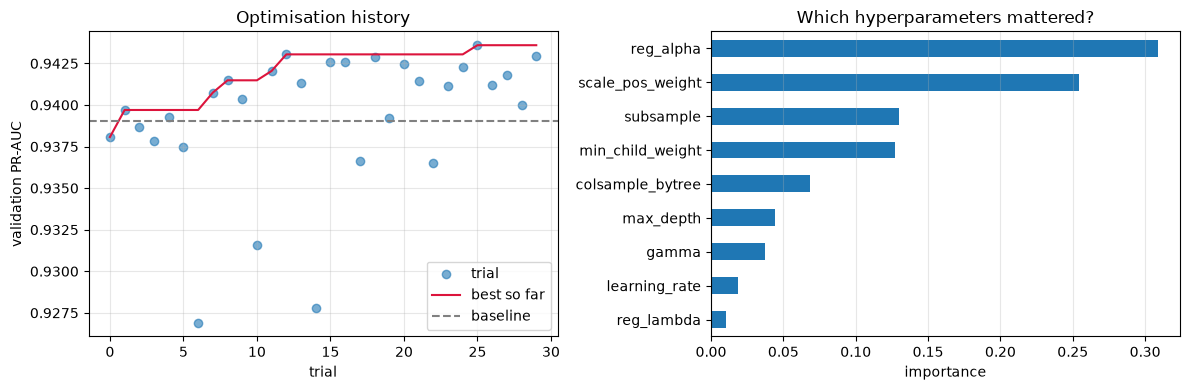

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

best_so_far = trials["value"].cummax()
axes[0].scatter(trials["number"], trials["value"], alpha=0.6, label="trial")
axes[0].plot(trials["number"], best_so_far, color="crimson", label="best so far")
axes[0].axhline(BASELINE_VALID_PR_AUC, ls="--", c="grey", label="baseline")
axes[0].set(xlabel="trial", ylabel="validation PR-AUC", title="Optimisation history")
axes[0].legend(); axes[0].grid(alpha=0.3)

importances = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
importances.plot.barh(ax=axes[1])
axes[1].set(xlabel="importance", title="Which hyperparameters mattered?")
axes[1].grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

In [67]:
print("Best trial:", study.best_trial.number)
print("Baseline validation PR-AUC:", BASELINE_VALID_PR_AUC)
print("Best tuned validation PR-AUC:", study.best_value)
print("Improvement:", study.best_value - BASELINE_VALID_PR_AUC)
print("Best parameters:", study.best_params)
print("Best iteration:", study.best_trial.user_attrs["best_iteration"])

Best trial: 25
Baseline validation PR-AUC: 0.9390272333448496
Best tuned validation PR-AUC: 0.9435948506643126
Improvement: 0.00456761731946298
Best parameters: {'learning_rate': 0.02403250761531903, 'max_depth': 8, 'min_child_weight': 8.657461486337178, 'subsample': 0.7767383717515863, 'colsample_bytree': 0.9003882524690208, 'reg_lambda': 0.0250736895360387, 'reg_alpha': 0.02336147431253895, 'gamma': 2.1282776816785116, 'scale_pos_weight': 6.277457716158702}
Best iteration: 8


In [68]:
best_params = study.best_params

print("Best validation PR-AUC:", study.best_value)
print("\nBest hyperparameters:")
for param, value in best_params.items():
    print(f"{param}: {value}")

Best validation PR-AUC: 0.9435948506643126

Best hyperparameters:
learning_rate: 0.02403250761531903
max_depth: 8
min_child_weight: 8.657461486337178
subsample: 0.7767383717515863
colsample_bytree: 0.9003882524690208
reg_lambda: 0.0250736895360387
reg_alpha: 0.02336147431253895
gamma: 2.1282776816785116
scale_pos_weight: 6.277457716158702


In [69]:
# Refit with the FULL recipe: best_params only holds the 9 sampled values, so the fixed
# settings from sample_params() (n_estimators, early stopping, eval_metric, ...) must be re-added.
final_params = dict(
    n_estimators=2000, eval_metric="aucpr", early_stopping_rounds=50,
    tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, **best_params,
)
final_model = fit_xgb(final_params)
valid_scores = final_model.predict_proba(valid[FEATURES])[:, 1]
test_scores = final_model.predict_proba(test[FEATURES])[:, 1]

# The refit must reproduce the number the search reported before we trust it.
assert abs(average_precision_score(y_valid, valid_scores) - study.best_value) < 1e-3, \
    "refit does not reproduce the best trial"
assert abs(final_model.best_iteration - study.best_trial.user_attrs["best_iteration"]) <= 2

# Threshold is computed on validation (max-F1), not typed by hand.
precision, recall, thresholds = precision_recall_curve(y_valid, valid_scores)
f1_curve = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
FINAL_THRESHOLD = float(thresholds[int(np.argmax(f1_curve))])
best_iteration = int(final_model.best_iteration)
print(f"threshold (max-F1 on validation): {FINAL_THRESHOLD:.4f} | best_iteration: {best_iteration}")

valid_metrics = evaluate(y_valid, valid_scores, FINAL_THRESHOLD)
test_metrics = evaluate(y_test, test_scores, FINAL_THRESHOLD)

summary = pd.DataFrame({
    "baseline validation": {"PR-AUC": BASELINE_VALID_PR_AUC},
    "tuned validation": {"PR-AUC": valid_metrics["pr_auc"]},
    "tuned test": {"PR-AUC": test_metrics["pr_auc"]},
})
display(summary.round(4))

print(f"Final test metrics at threshold {FINAL_THRESHOLD:.4f}")
display(pd.DataFrame([test_metrics]).round(4))

cm = confusion_matrix(y_test, (test_scores >= FINAL_THRESHOLD).astype(int), labels=[0, 1])
display(pd.DataFrame(cm, index=["actual legit", "actual fraud"],
                     columns=["predicted legit", "predicted fraud"]))
print(f"Caught {test_metrics['tp']} of {int(y_test.sum())} frauds; "
      f"missed {test_metrics['fn']}; false alarms: {test_metrics['fp']}.")

threshold (max-F1 on validation): 0.2161 | best_iteration: 8


,baseline validation,tuned validation,tuned test
PR-AUC,0.9390,0.9436,0.9845


Final test metrics at threshold 0.2161


,pr_auc,roc_auc,precision,recall,f1,tp,fp,fn,tn
0,0.9845,0.9983,0.9879,0.8581,0.9185,3441,42,569,404025


,predicted legit,predicted fraud
actual legit,404025,42
actual fraud,569,3441


Caught 3441 of 4010 frauds; missed 569; false alarms: 42.


In [70]:
MODEL_PATH = MODEL_DIR / "xgb_fraud_tuned.json"
final_model.save_model(MODEL_PATH)

with mlflow.start_run(run_id=PARENT_RUN_ID):
    mlflow.log_params({
        "final_model": "xgboost-tuned",
        "final_threshold": FINAL_THRESHOLD,
        "best_iteration": best_iteration,
    })
    mlflow.log_metrics({
        "final_valid_pr_auc": float(valid_metrics["pr_auc"]),
        "final_test_pr_auc": float(test_metrics["pr_auc"]),
        "final_test_precision": float(test_metrics["precision"]),
        "final_test_recall": float(test_metrics["recall"]),
        "final_test_f1": float(test_metrics["f1"]),
    })
    mlflow.log_artifact(str(MODEL_PATH), artifact_path="model")

meta_tuned = {
    "model": "xgboost-tuned",
    "feature_set": meta["feature_set"],
    "features": FEATURES,
    "threshold": FINAL_THRESHOLD,
    "params": {k: (float(v) if isinstance(v, (float, np.floating)) else v)
               for k, v in final_params.items()
               if k not in ("n_jobs", "tree_method")},
    "best_iteration": best_iteration,   # taken from the saved model, not from the study
    "split": meta["split"],
    "baseline_valid_pr_auc": float(BASELINE_VALID_PR_AUC),
    "validation_metrics": {k: float(v) for k, v in valid_metrics.items()},
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "mlflow_run_id": PARENT_RUN_ID,
}
(MODEL_DIR / "model_meta_tuned.json").write_text(json.dumps(meta_tuned, indent=2))
trials.to_csv(MODEL_DIR / "optuna_trials.csv", index=False)

# Quick check: the saved model reloads and produces the same scores.
reloaded = xgb.XGBClassifier()
reloaded.load_model(MODEL_PATH)
check_scores = reloaded.predict_proba(test[FEATURES].head(1000))[:, 1]
assert np.allclose(check_scores, test_scores[:1000], atol=1e-6)

print("Saved model:", MODEL_PATH)
print("Saved metadata:", MODEL_DIR / "model_meta_tuned.json")
print("Saved trial results:", MODEL_DIR / "optuna_trials.csv")

Saved model: ../models/xgb_fraud_tuned.json
Saved metadata: ../models/model_meta_tuned.json
Saved trial results: ../models/optuna_trials.csv
